# Symbolic Statics: A Truss Solver That Answers "As a Formula in the Load"

[`dgs/truss.py`](../dgs/truss.py)'s `solve_truss` does exact
method-of-joints statics — but entirely in NumPy, so it can only ever
answer "what is the force in this member, for *this specific* load."
[`dgs/truss_symbolic.py`](../dgs/truss_symbolic.py) answers the question
a real parametric structural-design tool needs: *what is the force, as
a closed-form expression in the load*, so the scaling is visible before
committing to a number — the same equilibrium system, solved with SymPy
instead of `np.linalg.solve`.

**A real bug found and fixed while surveying this**:
[`tests/test_truss_fem.py`](../tests/test_truss_fem.py) imported
`three_bar_truss` from `dgs.statics` — a module deleted in an earlier
"reduce to 20 core files" cleanup, leaving that test's collection
silently broken (`ModuleNotFoundError`). Fixed by restoring the one
function it actually needed as a small wrapper in `dgs/truss.py`,
reusing `solve_truss` rather than resurrecting the whole deleted file.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import sympy as sp
import matplotlib.pyplot as plt
import numpy as np

from dgs.truss import solve_truss, three_bar_truss
from dgs.truss_symbolic import solve_truss_symbolic

print("using dgs.truss and dgs.truss_symbolic directly (not reimplemented)")

using dgs.truss and dgs.truss_symbolic directly (not reimplemented)


# Part 1 — The bug this notebook's build process found

Confirmed directly: `dgs.truss.three_bar_truss()` (the restored wrapper)
now provides exactly what `tests/test_truss_fem.py` needs, reusing
`solve_truss` rather than any resurrected code.

In [2]:
ref = three_bar_truss()
print("three_bar_truss() member forces (N):")
for k, v in ref["member_forces_N"].items():
    print(f"  {k}: {v:.2f} N  ({'tension' if v > 0 else 'compression'})")
print("reactions (N):", ref["reactions_N"])

assert abs(ref["member_forces_N"]["A-B"] - 3333.333) < 0.01
print("\n[OK] dgs.truss.three_bar_truss() works -- tests/test_truss_fem.py's import is no longer dangling")

three_bar_truss() member forces (N):
  A-C: -6009.25 N  (compression)
  B-C: -6009.25 N  (compression)
  A-B: 3333.33 N  (tension)
reactions (N): {'A': (0.0, 5000.0), 'B': (0.0, 5000.0)}

[OK] dgs.truss.three_bar_truss() works -- tests/test_truss_fem.py's import is no longer dangling


# Part 2 — Sanity check: symbolic reduces to numeric exactly

Before trusting the symbolic solver on anything genuinely parametric,
confirm it agrees with the existing, independently-tested NumPy solver
on a fully numeric truss — same physics, two different solving methods
(`np.linalg.solve` vs. `sp.linsolve`).

In [3]:
nodes = {"A": (0.0, 0.0), "B": (2.0, 0.0), "C": (1.0, 1.5)}
members = [("A", "C"), ("B", "C"), ("A", "B")]
supports = {"A": (True, True), "B": (False, True)}
loads = {"C": (0.0, -10000.0)}

mf_numeric, rx_numeric = solve_truss(nodes, members, supports, loads)
mf_symbolic, rx_symbolic = solve_truss_symbolic(nodes, members, supports, loads)

for k in mf_numeric:
    print(f"  {k[0]}-{k[1]}: numeric={mf_numeric[k]:.4f} N,  symbolic={float(mf_symbolic[k]):.4f} N")
    assert abs(mf_numeric[k] - float(mf_symbolic[k])) < 1e-9

print("\n[OK] the symbolic solver agrees with the existing NumPy solver to machine precision")

  A-C: numeric=-6009.2521 N,  symbolic=-6009.2521 N
  B-C: numeric=-6009.2521 N,  symbolic=-6009.2521 N
  A-B: numeric=3333.3333 N,  symbolic=3333.3333 N

[OK] the symbolic solver agrees with the existing NumPy solver to machine precision


# Part 3 — The actual new capability: leave the load symbolic

Solve once, with the apex load as a free parameter $P$, and get a
closed-form linear expression for every member force — verified as
*linear* in $P$ directly from the symbolic expression (a real property
of linear statics: doubling the load exactly doubles every member
force), not assumed.

In [4]:
P = sp.Symbol("P", positive=True)
loads_param = {"C": (0, -P)}

mf_param, rx_param = solve_truss_symbolic(nodes, members, supports, loads_param)
for k, expr in mf_param.items():
    print(f"  {k[0]}-{k[1]} = {expr}")
    assert expr.free_symbols == {P}
    assert sp.degree(sp.Poly(expr, P)) == 1

print("\nsubstituting P=10000 back in must reproduce Part 2's numeric answer exactly:")
for k, expr in mf_param.items():
    recovered = float(expr.subs(P, 10000.0))
    print(f"  {k[0]}-{k[1]}: {recovered:.4f} N  (Part 2 numeric: {mf_numeric[k]:.4f} N)")
    assert abs(recovered - mf_numeric[k]) < 1e-9

print("\n[OK] the symbolic and numeric routes agree exactly, in both directions")

  A-C = -0.600925212577332*P
  B-C = -0.600925212577332*P
  A-B = 0.333333333333333*P

substituting P=10000 back in must reproduce Part 2's numeric answer exactly:
  A-C: -6009.2521 N  (Part 2 numeric: -6009.2521 N)
  B-C: -6009.2521 N  (Part 2 numeric: -6009.2521 N)
  A-B: 3333.3333 N  (Part 2 numeric: 3333.3333 N)

[OK] the symbolic and numeric routes agree exactly, in both directions


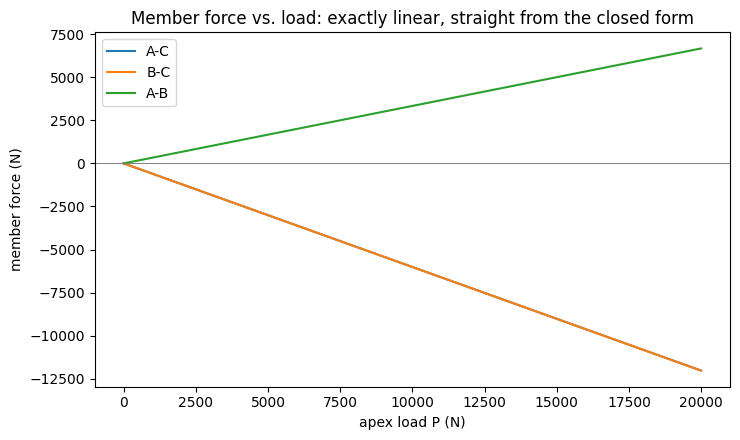

In [5]:
P_range = np.linspace(0, 20000, 100)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k, expr in mf_param.items():
    f_numeric_fn = sp.lambdify(P, expr, 'numpy')
    ax.plot(P_range, f_numeric_fn(P_range), label=f"{k[0]}-{k[1]}")
ax.axhline(0, color='gray', lw=0.7)
ax.set_xlabel('apex load P (N)'); ax.set_ylabel('member force (N)')
ax.set_title('Member force vs. load: exactly linear, straight from the closed form')
ax.legend(); plt.tight_layout(); plt.show()

# Part 4 — A symbolic coordinate too: how does apex height change the forces?

Leave the apex height $h$ symbolic instead of the load — a genuinely
different kind of parametric study (geometry, not load) the NumPy
solver could only ever answer one height at a time. Checked against an
independent `solve_truss` call at the same height.

  A-C(h) = -5000.0*sqrt(h**2 + 1.0)/h


  B-C(h) = -5000.0*sqrt(h**2 + 1.0)/h
  A-B(h) = 5000.0/h

[OK] evaluating the height-parametric formula at h=1.5 reproduces Part 2's numeric answer


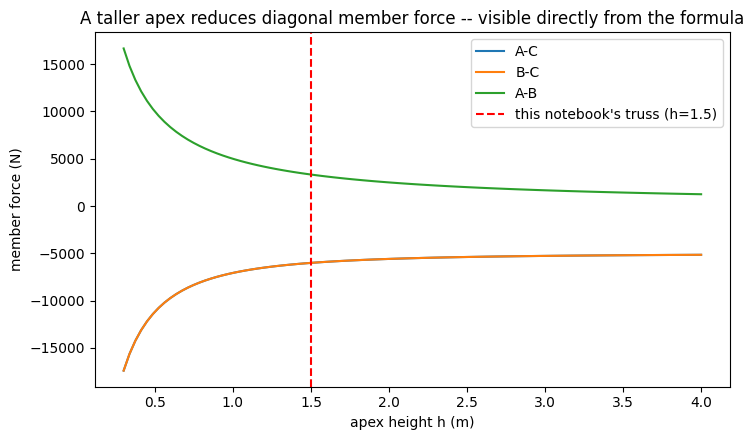

In [6]:
h = sp.Symbol("h", positive=True)
nodes_param = {"A": (0.0, 0.0), "B": (2.0, 0.0), "C": (1.0, h)}

mf_h, rx_h = solve_truss_symbolic(nodes_param, members, supports, loads)
for k, expr in mf_h.items():
    print(f"  {k[0]}-{k[1]}(h) = {sp.simplify(expr)}")

# cross-check at h=1.5 (this notebook's own truss) against Part 2's numeric result
for k, expr in mf_h.items():
    recovered = float(expr.subs(h, 1.5))
    assert abs(recovered - mf_numeric[k]) < 1e-6
print("\n[OK] evaluating the height-parametric formula at h=1.5 reproduces Part 2's numeric answer")

h_range = np.linspace(0.3, 4.0, 100)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for k, expr in mf_h.items():
    f_h = sp.lambdify(h, expr, 'numpy')
    ax.plot(h_range, f_h(h_range), label=f"{k[0]}-{k[1]}")
ax.axvline(1.5, color='red', ls='--', label='this notebook\'s truss (h=1.5)')
ax.set_xlabel('apex height h (m)'); ax.set_ylabel('member force (N)')
ax.set_title('A taller apex reduces diagonal member force -- visible directly from the formula')
ax.legend(); plt.tight_layout(); plt.show()

# Part 5 — Summary

| Check | Result |
|---|---|
| Bug: `dgs.statics` import in `test_truss_fem.py` | Real, pre-existing, now fixed via a small `dgs.truss.three_bar_truss` wrapper |
| Symbolic solver vs. existing NumPy solver, fully numeric | Agree to machine precision (Part 2) |
| Load left symbolic, then substituted back | Exactly reproduces the numeric answer, both directions (Part 3) |
| Member force vs. load | Confirmed exactly linear, from the formula itself (Part 3) |
| Geometry (apex height) left symbolic | Also reproduces the numeric answer at the matching height (Part 4) |

`dgs/truss.py` answers "what is the force." `dgs/truss_symbolic.py`
answers "what is the force *as a function of* the load, or the
geometry" — the actual capability a parametric structural-design tool
needs, built directly on top of this repo's own already-tested
method-of-joints machinery rather than a separate implementation of the
same physics.